<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_%D0%9B%D0%A0_7_%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%80%D1%8F%D1%82%D1%83%D0%B2%D0%B0%D1%82%D0%B8_%D0%BF%D1%80%D0%B8%D0%BD%D1%86%D0%B5%D1%81%D1%83_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [ ]:
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 18.1MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape

# Перші 5 рядків датасету
display(df.head())

# Інформація про структуру та типи даних
df.info()

# Розмір датасету (рядки, стовпці)
print('Розмір датасету:', df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету: (2338, 14)


In [ ]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()

# Перевірка пропущених значень
print('Пропущені значення:')
display(df.isnull().sum())

# Загальна кількість пропусків
print('Усього пропусків:', df.isnull().sum().sum())

# Перевірка дублікатів
print('Кількість дублікатів:', df.duplicated().sum())

Пропущені значення:


,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Усього пропусків: 0
Кількість дублікатів: 0


In [ ]:
# TODO: виведіть описову статистику
# Підказка: describe()

# Описова статистика датасету
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

Висновок:

Датасет містить 2338 записів і 14 стовпців, з яких 13 є числовими ознаками, а один — цільовою змінною Cured. Пропущені значення та дублікати відсутні. Усі ознаки інгредієнтів мають тип float64, а цільова змінна — int64. Значення ознак мають різні діапазони та середні значення. Загалом дані мають хорошу якість і не потребують додаткового очищення від пропусків або дублікатів.


### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)

# Відокремлення ознак від цільової змінної
X = df.drop('Cured', axis=1)
y = df['Cured']

# Поділ на навчальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Перевірка розмірів вибірок
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (1870, 13)
X_test: (468, 13)
y_train: (1870,)
y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [ ]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train

# Підрахунок кількості спостережень кожного класу
print(y_train.value_counts())

# Відображення у відсотках
print('\nЧастка класів (%):')
print((y_train.value_counts(normalize=True) * 100).round(2))

Cured
0    946
1    924
Name: count, dtype: int64

Частка класів (%):
Cured
0    50.59
1    49.41
Name: proportion, dtype: float64


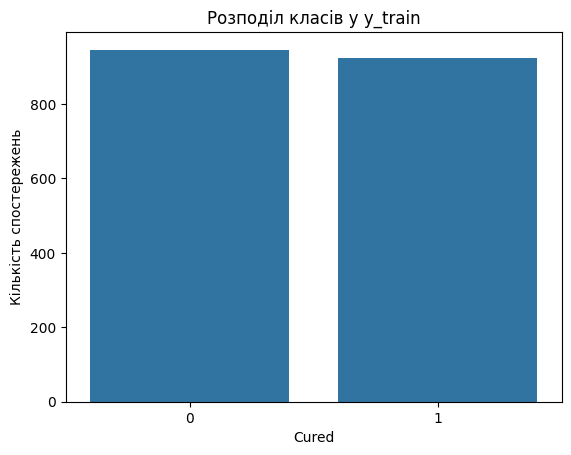

In [ ]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)

# Візуалізація розподілу класів у навчальній вибірці
sns.countplot(x=y_train)

plt.title('Розподіл класів у y_train')
plt.xlabel('Cured')
plt.ylabel('Кількість спостережень')
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Висновок:

Класи є збалансованими, оскільки кількість об'єктів майже однакова: 946 для класу `0` (50,59%) та 924 для класу `1` (49,41%). Значного дисбалансу немає, тому модель матиме приблизно однакову кількість прикладів для навчання кожного класу. Це зменшує ризик того, що модель буде надавати перевагу одному класу.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

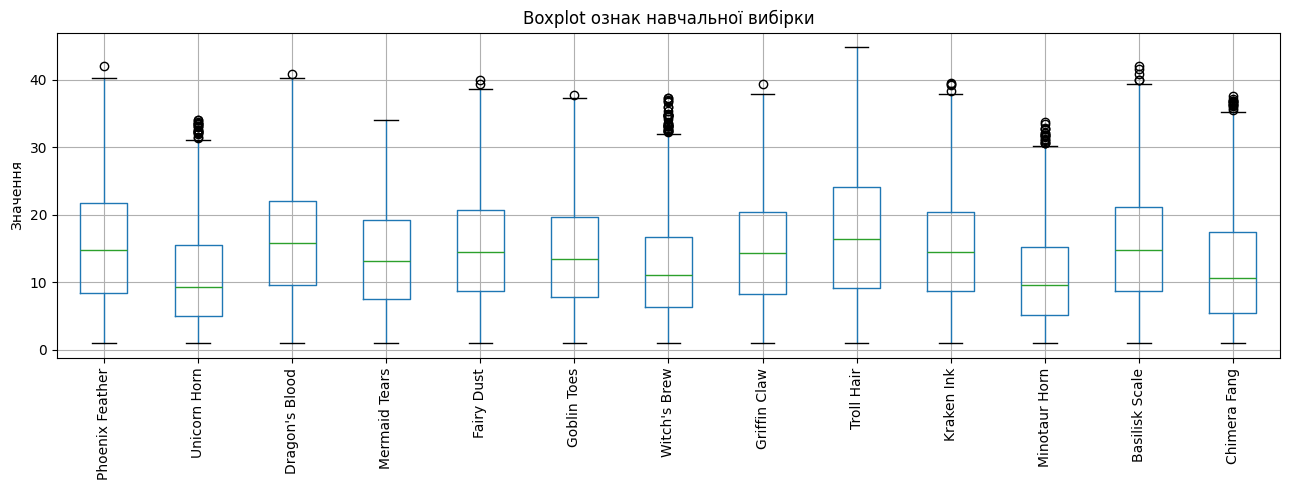

In [ ]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)

# Побудова діаграм розмаху для всіх ознак X_train
X_train.boxplot(figsize=(13, 5), rot=90)

plt.title('Boxplot ознак навчальної вибірки')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [ ]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням

# Обчислення Q1, Q3 та IQR
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

# Межі для визначення викидів
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Підрахунок кількості викидів
outliers_count = (
    (X_train < lower_bound) | (X_train > upper_bound)
).sum()

# Формування та сортування таблиці
outliers_table = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Кількість викидів': outliers_count
})

outliers_table = outliers_table.sort_values(
    by='Кількість викидів',
    ascending=False
)

display(outliers_table.round(2))

,Q1,Q3,IQR,Кількість викидів
Witch's Brew,6.40,16.70,10.30,33
Unicorn Horn,5.10,15.50,10.40,20
Minotaur Horn,5.20,15.28,10.07,18
Chimera Fang,5.50,17.50,12.00,13
Basilisk Scale,8.70,21.10,12.40,5
Kraken Ink,8.80,20.50,11.70,4
Fairy Dust,8.80,20.78,11.97,2
Phoenix Feather,8.50,21.70,13.20,1
Dragon's Blood,9.60,22.08,12.48,1
Griffin Claw,8.30,20.40,12.10,1


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

Висновок:

Найбільше потенційних викидів виявлено в ознаці `Witch's Brew` — 33, `Unicorn Horn` — 20 та `Minotaur Horn` — 18. Видаляти такі рядки без перевірки не варто, оскільки вони можуть містити важливу інформацію та бути реальними особливостями даних, а не помилками. Тому всі виявлені спостереження залишаються в датасеті для подальшого навчання моделей.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

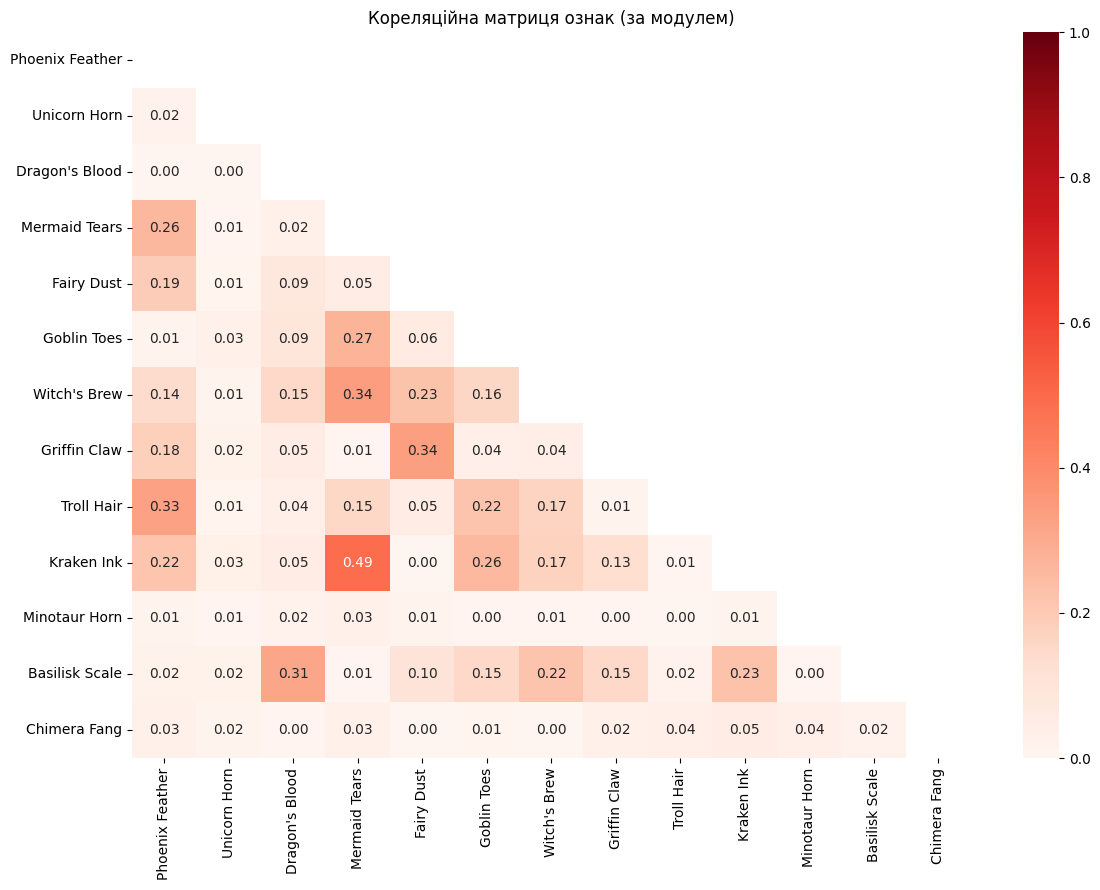

In [ ]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1

# Обчислення абсолютної кореляційної матриці
mtx = X_train.corr().abs()

# Маска для приховування верхнього трикутника
mask = np.triu(np.ones_like(mtx, dtype=bool))

# Побудова теплової карти кореляцій
plt.figure(figsize=(12, 9))
sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap='Reds',
    vmin=0,
    vmax=1,
    fmt='.2f'
)

plt.title('Кореляційна матриця ознак (за модулем)')
plt.tight_layout()
plt.show()

In [ ]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()

# Об'єднання ознак із цільовою змінною
train_corr = pd.concat([X_train, y_train], axis=1).corr()

# Кореляція кожної ознаки з Cured
cured_corr = train_corr['Cured'].drop('Cured').sort_values(
    key=abs,
    ascending=False
)

display(cured_corr.to_frame(name='Кореляція з Cured').round(3))

,Кореляція з Cured
Troll Hair,0.489
Witch's Brew,0.247
Goblin Toes,0.053
Chimera Fang,0.047
Basilisk Scale,-0.042
Kraken Ink,-0.027
Minotaur Horn,0.022
Phoenix Feather,0.021
Fairy Dust,0.014
Dragon's Blood,0.010


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

Висновок:

Найсильніший зв'язок між ознаками спостерігається між Mermaid Tears і Kraken Ink (0,49), а також між Fairy Dust і Griffin Claw (0,34). Найбільшу кореляцію з цільовою змінною Cured має Troll Hair (0,489), на другому місці — Witch's Brew (0,247). Інші ознаки мають дуже слабкий зв'язок із результатом лікування.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled

# Створення об'єкта стандартизації
scaler = StandardScaler()

# Стандартизація навчальної та тестової вибірок
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report

# Створення та навчання моделі логістичної регресії
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

# Прогнозування на тестовій вибірці
y_pred = model.predict(X_test_scaled)

# Оцінювання точності моделі
print('Accuracy:', accuracy_score(y_test, y_pred))

# Звіт про якість класифікації
print(classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

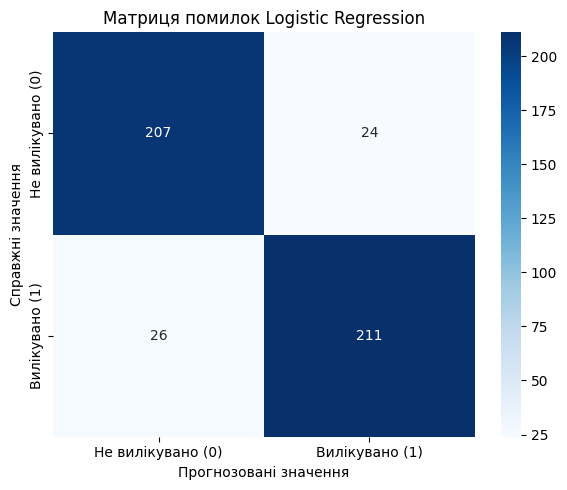

In [ ]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)

# Обчислення матриці помилок
conf = confusion_matrix(y_test, y_pred)

# Побудова теплової карти
plt.figure(figsize=(6, 5))
sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не вилікувано (0)', 'Вилікувано (1)'],
    yticklabels=['Не вилікувано (0)', 'Вилікувано (1)']
)

plt.title('Матриця помилок Logistic Regression')
plt.xlabel('Прогнозовані значення')
plt.ylabel('Справжні значення')
plt.tight_layout()
plt.show()

In [ ]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))

# Створення таблиці зі справжніми та передбаченими класами
results = pd.DataFrame({
    'Справжній клас': y_test.values,
    'Передбачений клас': y_pred
})

# Виведення 10 випадкових рядків
display(results.sample(10, random_state=42))

,Справжній клас,Передбачений клас
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

Висновок:

За результатами оцінювання Logistic Regression отримано точність прогнозування 89,3%. Аналіз матриці помилок показав, що модель частіше допускає помилки другого типу — 26 випадків, тоді як помилок першого типу було 24. Отже, Accuracy недостатньо для повної оцінки якості моделі, оскільки ця метрика не показує характер допущених помилок. Тому для більш детального аналізу також використовуються Precision, Recall та F1-score.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'newton-cg'],
    'max_iter': [100, 200, 500, 1000]
}

param_dist = {
    'C': np.logspace(-3, 2, 20),
    'solver': ['lbfgs', 'liblinear', 'newton-cg', 'saga'],
    'max_iter': [100, 200, 300, 500, 1000]
}

In [ ]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

grid_search = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=3,
    scoring='accuracy'
)

grid_search.fit(X_train_scaled, y_train)

print('Найкращі параметри:', grid_search.best_params_)
print('Найкраща Accuracy:', grid_search.best_score_)

Найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща Accuracy: 0.8673927508197171


In [ ]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42
)

random_search.fit(X_train_scaled, y_train)

print('Найкращі параметри:', random_search.best_params_)
print('Найкраща Accuracy:', random_search.best_score_)

Найкращі параметри: {'solver': 'liblinear', 'max_iter': 300, 'C': np.float64(16.23776739188721)}
Найкраща Accuracy: 0.8673927508197171


In [ ]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report

best_model = grid_search.best_estimator_
# Або random_search.best_estimator_, якщо його результат кращий

y_pred_best = best_model.predict(X_test_scaled)

print('Accuracy:', accuracy_score(y_test, y_pred_best))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_best))

Accuracy: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

Висновок:

GridSearchCV обрав параметри C = 10, solver = 'lbfgs', max_iter = 100. RandomizedSearchCV обрав C ≈ 16.24, solver = 'liblinear', max_iter = 300. Обидва методи отримали однакову Accuracy — приблизно 86,74% під час перехресної перевірки.

Після застосування найкращої моделі точність на тестовій вибірці становила 89,3%, як і в базової моделі. Отже, підбір параметрів не покращив якість прогнозування порівняно з базовою моделлю.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель

# Створення моделей
svc_model = SVC()
tree_model = DecisionTreeClassifier(random_state=42)

# Навчання трьох моделей
model.fit(X_train_scaled, y_train)
svc_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train, y_train)

# Отримання прогнозів
y_pred_lr = model.predict(X_test_scaled)
y_pred_svc = svc_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test)

# Порівняння моделей
results = pd.DataFrame({
    'Модель': ['Logistic Regression', 'SVC', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_tree)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_tree)
    ]
})

display(results.sort_values(by='F1-score', ascending=False))

# Визначення найкращої моделі
best_model_name = results.loc[results['F1-score'].idxmax(), 'Модель']
print('Найкраща модель:', best_model_name)

,Модель,Accuracy,F1-score
1,SVC,0.959402,0.960000
0,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.863248,0.863248


Найкраща модель: SVC


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
1\. Під час первинного аналізу встановлено, що набір даних містить 2338 рядків, 13 ознак і цільову змінну `Cured`. Пропущені значення та дублікати відсутні. Розподіл класів майже рівномірний, тому дані є збалансованими.

2\. Дослідження викидів на навчальній вибірці показало найбільшу їх кількість у `Witch's Brew` (33), `Unicorn Horn` (20) та `Minotaur Horn` (18). Їх не видаляли, оскільки вони можуть бути природними значеннями. Найсильніша кореляція між ознаками спостерігається у `Mermaid Tears` і `Kraken Ink` (0,49). Найбільший зв'язок із цільовою змінною `Cured` має `Troll Hair` (0,489).

3\. Базова логістична регресія показала Accuracy = 89,32%, а F1-score для обох класів становив приблизно 0,89. Це свідчить про достатньо високу якість класифікації.

4\. Підбір гіперпараметрів за допомогою GridSearchCV та RandomizedSearchCV не покращив якість моделі. Обидва методи отримали Accuracy приблизно 86,74% під час перехресної перевірки. На тестовій вибірці результат залишився таким самим, як у базової моделі, — 89,32%.

5\. Найкращою моделлю виявилася SVC, яка отримала Accuracy = 95,94% та F1-score = 0,96. Для порівняння, Logistic Regression показала 89,32% і 0,894, а Decision Tree — 86,32% і 0,863 відповідно. Отже, SVC забезпечила найкращу точність прогнозування та найкращий баланс між Precision і Recall.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.